In [1]:
import cv2
from skimage.util import random_noise
import numpy as np
from matplotlib import pyplot as plt

Pixel (100,100) BGR: 253 236 197


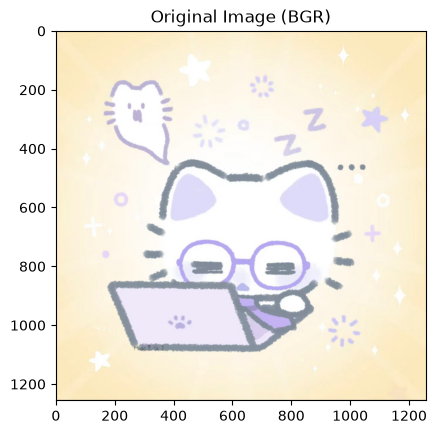

In [11]:
img = cv2.imread('cat.jpg')

# 获取像素点 (100, 100) 的 BGR 值
(b, g, r) = img[100, 100]
print('Pixel (100,100) BGR:', b, g, r)

plt.imshow(img)
plt.title('Original Image (BGR)')
plt.savefig('result/original_bgr.jpg', dpi=300)
plt.show()

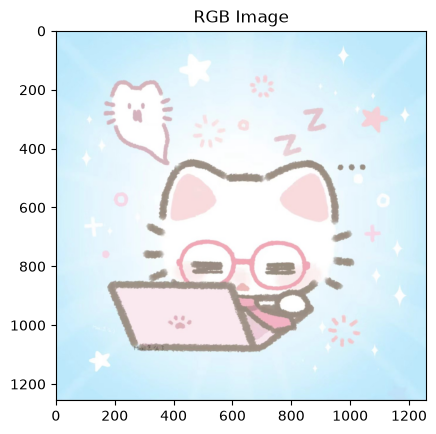

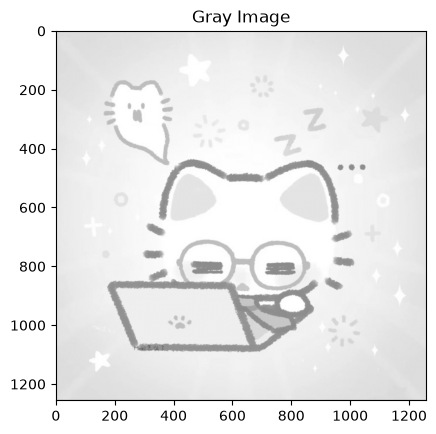

In [12]:
# BGR → RGB
rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(rgb_img)
plt.title('RGB Image')
plt.savefig('result/rgb_image.jpg', dpi=300)
plt.show()

# BGR → Gray
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_img, cmap='gray')
plt.title('Gray Image')
plt.savefig('result/gray_image.jpg', dpi=300)
plt.show()

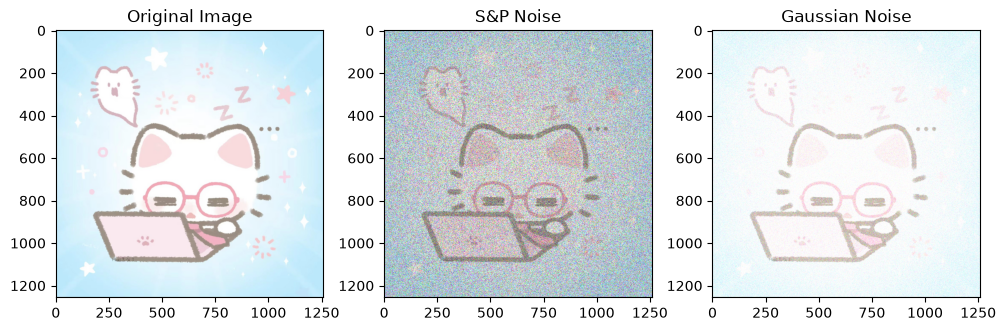

In [13]:
# 椒盐噪声
sp_noise_img = random_noise(rgb_img, mode='s&p', amount=0.4)

# 高斯噪声
gus_noise_img = random_noise(rgb_img, mode='gaussian', mean=0.2, var=0.03)

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(rgb_img)
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(sp_noise_img)
plt.title('S&P Noise')

plt.subplot(1, 3, 3)
plt.imshow(gus_noise_img)
plt.title('Gaussian Noise')

plt.tight_layout()
plt.savefig('result/noise_comparison.jpg', dpi=300)
plt.show()

In [14]:
# 均值滤波
mean_sp = cv2.blur(sp_noise_img, (5, 5))
mean_gus = cv2.blur(gus_noise_img, (5, 5))

# 中值滤波（需 uint8）
mid_sp = cv2.medianBlur((sp_noise_img * 255).astype(np.uint8), 5)
mid_gus = cv2.medianBlur((gus_noise_img * 255).astype(np.uint8), 5)

# 高斯滤波
gauss_sp = cv2.GaussianBlur((sp_noise_img * 255).astype(np.uint8), (5, 5), 0)
gauss_gus = cv2.GaussianBlur((gus_noise_img * 255).astype(np.uint8), (5, 5), 0)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.18980392156862785..1.000000000000002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.5323696302418405..1.0000000000000049].


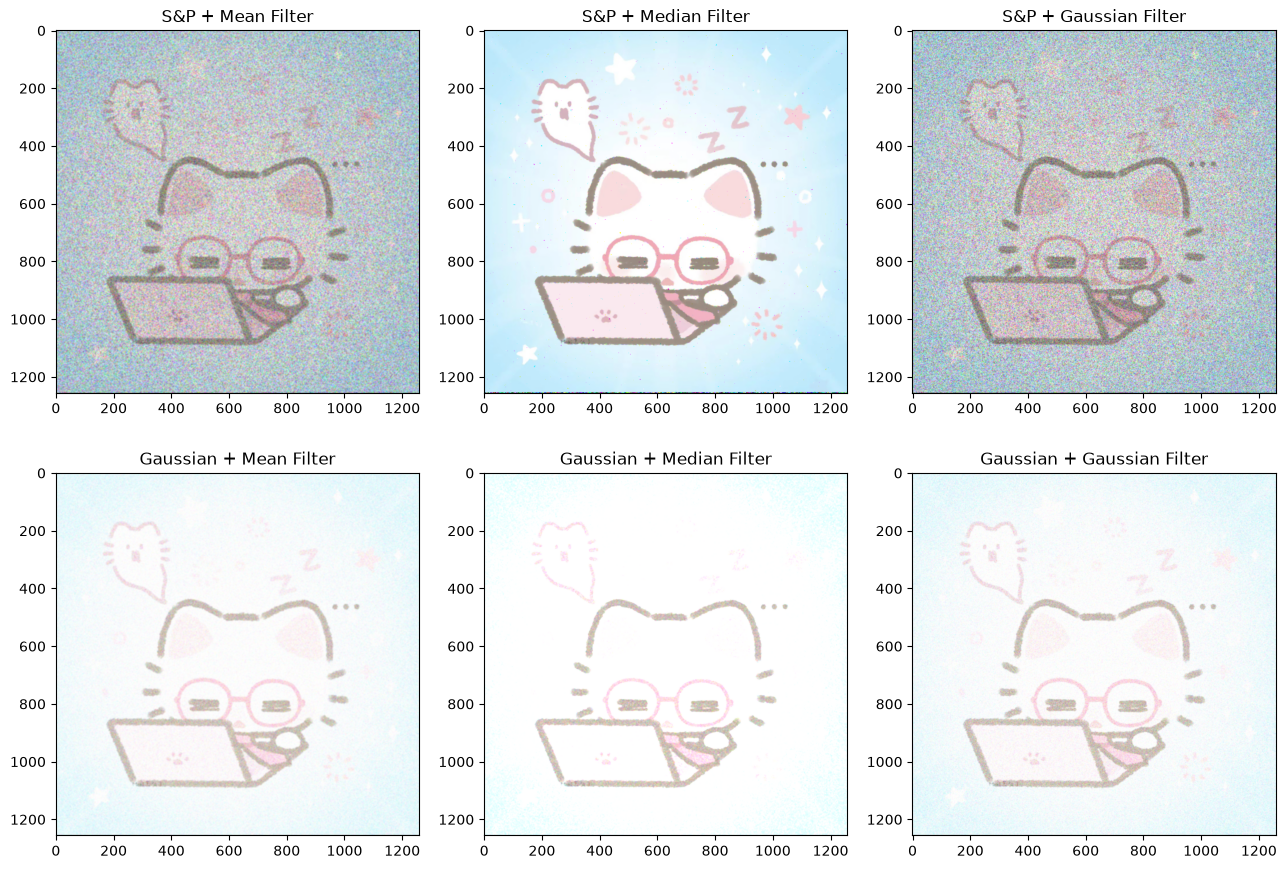

In [15]:
plt.figure(figsize=(13, 9))

# 椒盐噪声
plt.subplot(2, 3, 1)
plt.imshow(mean_sp)
plt.title('S&P + Mean Filter')

plt.subplot(2, 3, 2)
plt.imshow(mid_sp)
plt.title('S&P + Median Filter')

plt.subplot(2, 3, 3)
plt.imshow(gauss_sp)
plt.title('S&P + Gaussian Filter')

# 高斯噪声
plt.subplot(2, 3, 4)
plt.imshow(mean_gus)
plt.title('Gaussian + Mean Filter')

plt.subplot(2, 3, 5)
plt.imshow(mid_gus)
plt.title('Gaussian + Median Filter')

plt.subplot(2, 3, 6)
plt.imshow(gauss_gus)
plt.title('Gaussian + Gaussian Filter')

plt.tight_layout()
plt.savefig('result/filter_results_2x3.jpg', dpi=300)
plt.show()

In [16]:
def manual_median_filter_color(image, kernel_size=5):
    """
    手动实现彩色图像的中值滤波
    image: 输入彩色图像 (H, W, 3)
    kernel_size: 滤波窗口大小
    """
    pad = kernel_size // 2
    filtered_img = np.zeros_like(image)

    for c in range(3):
        channel = image[:, :, c]
        padded = np.pad(channel, pad_width=pad, mode='edge')
        for i in range(channel.shape[0]):
            for j in range(channel.shape[1]):
                region = padded[i:i+kernel_size, j:j+kernel_size]
                filtered_img[i, j, c] = np.median(region)

    return filtered_img

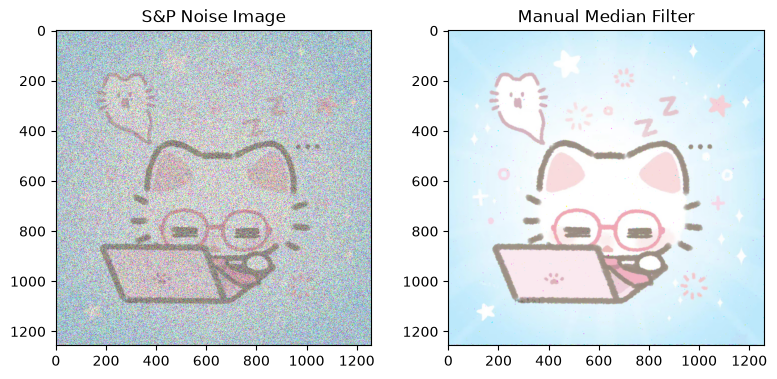

In [17]:
manual_mid = manual_median_filter_color((sp_noise_img * 255).astype(np.uint8), kernel_size=5)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sp_noise_img)
plt.title('S&P Noise Image')

plt.subplot(1, 2, 2)
plt.imshow(manual_mid)
plt.title('Manual Median Filter')

plt.tight_layout()
plt.savefig('result/manual_median.jpg', dpi=300)
plt.show()